In [1]:
import os
import pickle
import matplotlib.pyplot as plt

In [79]:
def plot_scores(evaluation_dict, MZ = "all", suffix = "", qcd = True):
    """Plot scores for all Mediator masses and rinv in one plot

    Args:
        evaluation_dict(dict): a dict created in Evaluate_model()
        name(str): Name of the training for the saving of the pdf
       

    Returns:
    """
        

    line_styles = {
        '0.3': '-',
        '0.5': '--',
        '0.7': ':'
    }

    colors = {
        '700': 'plum',        # Plum
        '800': '#E63946',     # Firebrick
        '900': '#F4A261',     # Tangerine yellow
        '1000': '#A8DADC',    # Powder blue
        '1500': '#457B9D',    # Steel blue
        '3000': '#1D3557',    # Dark blue
        'qcd': 'dimgrey',
    }
 
    # Iterate over each key in roc dictionary and add the scores
    for key in evaluation_dict:
        parts = key.split("_")
        if (MZ != "all") and (parts[1] != MZ):
            continue
        label = f"$M_{{Z'}} = {parts[1]},  r_{{inv}} = 0.{parts[2].split('p')[1]}$"
        rinv_value = f"0.{parts[2].split('p')[1]}"
        m_z = parts[1]
        score_sig = []
        score_bkg = []
        for label, score in zip(evaluation_dict[key]["target_labels"], evaluation_dict[key]["scores"]):
            if label == 1:
                score_sig.append(score)
            elif (qcd == True) & (label == 0):
                score_bkg.append(score)
        if qcd == True:
            plt.hist(score_bkg,bins = 50 , color=colors["qcd"], linewidth = 0.9, linestyle='-', histtype = 'step', label="QCD")
        plt.hist(score_sig,bins = 50 , color=colors[m_z], linewidth = 0.9, linestyle=line_styles[rinv_value], histtype = 'step', label=label)
        qcd = False

    # Create dummy plots for separate legends
    # Dummy plots for MZ values
    legend_handles_mz = [plt.Line2D([0], [1], color=color, linewidth = 0.9,linestyle='-', label=f"$M_{{Z'}} = {m_z}$") for m_z, color in colors.items()]
    # Dummy plots for rinv values
    legend_handles_rinv = [plt.Line2D([0], [1], color='black',linewidth = 0.9, linestyle=linestyle, label=f"$r_{{inv}} = {rinv}$") for rinv, linestyle in line_styles.items()]

    additional_handle_qcd = plt.Line2D([0], [1], color='dimgrey', linewidth=0.9, linestyle='-', label='QCD')

    # Combine all legend handles
    legend_handles_rinv = legend_handles_rinv + [additional_handle_qcd]

    # Plot the scores in a histogram
    plt.xlabel("Score")
    plt.ylabel("Number of Graphs")

    # Create the first legend for MZ values
    if MZ == "all":
        first_legend = plt.legend(handles=legend_handles_mz, loc=[0.735,0.52])
        ax = plt.gca().add_artist(first_legend)
    else:
        plt.title(f"$M_{{Z'}}$ = {MZ} GeV")

    plt.legend(handles=legend_handles_rinv, loc=[0.5,0.72])
    #plt.grid()

   
    output_path = "/t3home/rhampp/SVJ_GNN/output/LundNet5+_SVJ-QCD_vs2"
    outout_plot_name ="LundNet5+_SVJ-QCD_vs2" + suffix +"_score.png"
    plt.savefig(os.path.join( output_path,outout_plot_name), dpi=1200)
    # plt.close()




In [68]:
path = os.getcwd()

In [73]:
with open(path + "/output/LundNet5+_SVJ-QCD_vs2/_eval_HT300excluded_ROC_AUC.pkl", 'rb') as file:
    evaluation_dict = pickle.load(file)

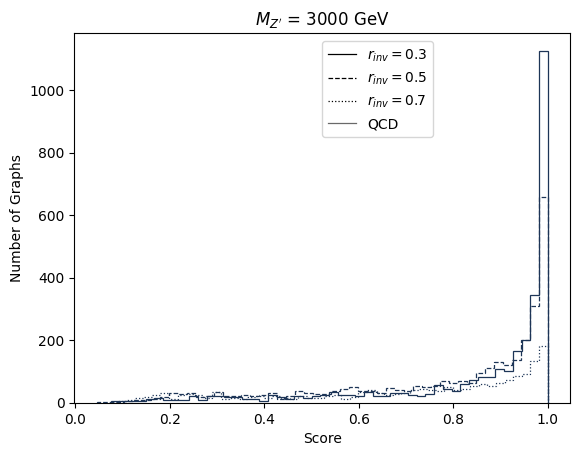

In [85]:
plot_scores(evaluation_dict,MZ = "3000",suffix = "_MZ3000", qcd = False)